Decision Tree model to classify 

Best Hyperparameters: {'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 4, 'min_samples_split': 10}
Cross-Validation Scores: [0.75       0.75       0.79166667 0.625      0.79166667]
Mean Accuracy: 0.7416666666666666
Test Set Accuracy: 0.7562862669245648
              precision    recall  f1-score   support

           0       0.09      0.56      0.15        41
           1       0.98      0.76      0.86       993

    accuracy                           0.76      1034
   macro avg       0.53      0.66      0.51      1034
weighted avg       0.94      0.76      0.83      1034



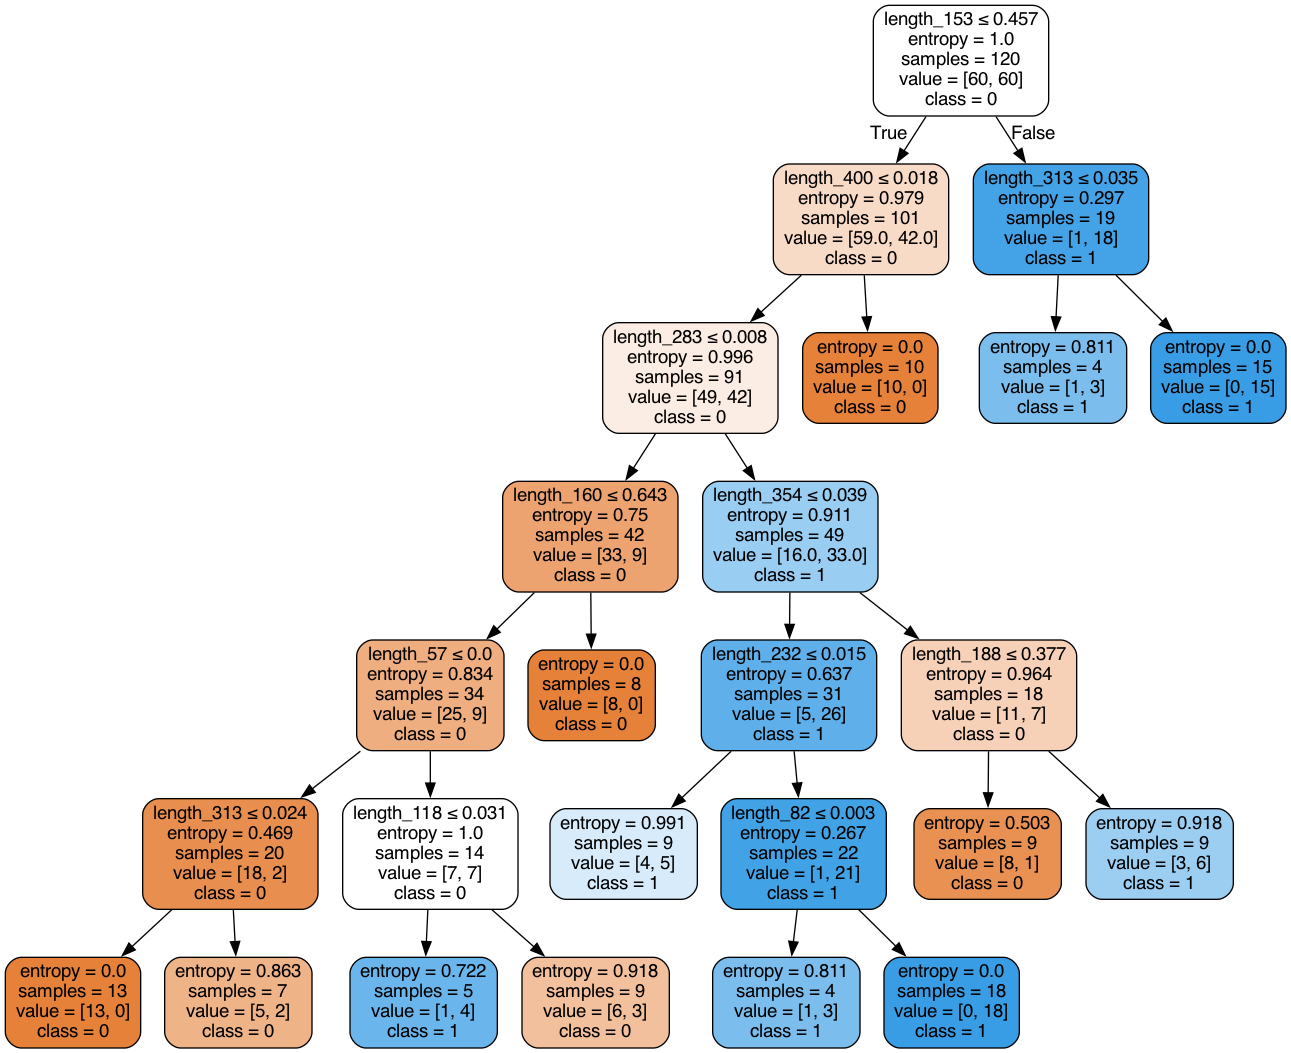

In [1]:
# --- project-root bootstrap: make this notebook CWD-independent (auto-added) ---
import os as _os
_root = _os.path.abspath(_os.getcwd())
while not _os.path.exists(_os.path.join(_root, 'data', 'raw', 'Train_Set.csv')) and _root != _os.path.dirname(_root):
    _root = _os.path.dirname(_root)
_os.chdir(_root)
# --- end bootstrap ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_score
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier # Import Decision Tree Classifier
from sklearn.tree import export_graphviz
from six import StringIO  
from IPython.display import Image  
import pydotplus
from sklearn.model_selection import GridSearchCV


train = pd.read_csv('data/raw/Train_Set.csv') #, delimiter=',', dtype=None, encoding=None )
column_names = train.columns.tolist()
column_names = column_names[:-1]
#print(column_names)

train['class_label'] = train['class_label'].replace(['healthy', 'early stage cancer', 'screening stage cancer', 'mid stage cancer', 'late stage cancer'], [0, 1, 1, 1, 1])
train_x = train.iloc[:,:-1]
train_y = train.iloc[:,-1]


test = pd.read_csv('data/raw/Test_Set.csv') #, delimiter = ',', dtype = None, encoding = None)
test['class_label'] = test['class_label'].replace(['healthy', 'early stage cancer', 'screening stage cancer', 'mid stage cancer', 'late stage cancer'], [0, 1, 1, 1, 1])
test_x = test.iloc[:,:-1]
test_y = test.iloc[:,-1]

undersample = RandomUnderSampler(sampling_strategy = 1, random_state=42)

train_x , train_y = undersample.fit_resample(train_x, train_y)
# NOTE: never resample the test set - it must keep the real class distribution

# Define the grid of hyperparameters
param_grid = {
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [None, 'sqrt', 'log2']
}

# Perform grid search
grid_search = GridSearchCV(estimator=DecisionTreeClassifier(criterion="entropy", random_state=42), param_grid=param_grid, cv=5, scoring='f1')
grid_search.fit(train_x, train_y)

# Get the best hyperparameters
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)

# Use the best model for prediction
best_clf = grid_search.best_estimator_

# Perform k-fold cross-validation
k = 5  # Number of folds
cv_scores = cross_val_score(best_clf, train_x, train_y, cv=k)

# Print the cross-validation scores
print("Cross-Validation Scores:", cv_scores)
print("Mean Accuracy:", cv_scores.mean())

# Evaluate the model on the test set
y_pred = best_clf.predict(test_x)
print("Test Set Accuracy:", metrics.accuracy_score(test_y, y_pred))
print(classification_report(test_y, y_pred))

# Visualize the decision tree
dot_data = StringIO()
export_graphviz(best_clf, out_file=dot_data, filled=True, rounded=True, special_characters=True, feature_names=train_x.columns, class_names=['0', '1'])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
if '"\\n"' in graph.obj_dict['nodes']:
    graph.del_node('"\\n"')
graph.write_png('cancer.png')
Image(graph.create_png())




Importing necessary libraries and modules to construct Decision tree model. 

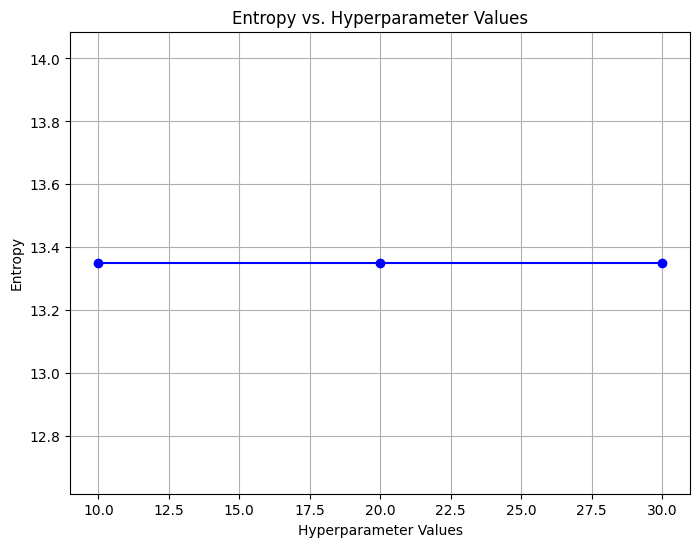

In [2]:
hyperparameter_values = [None, 10, 20, 30]  # Example values of the hyperparameter
entropy_values = []

for value in hyperparameter_values:
    # Train decision tree classifier with current hyperparameter value
    clf = DecisionTreeClassifier(criterion="entropy", max_depth=value, random_state=42)
    clf.fit(train_x, train_y)
    
    # Calculate entropy
    entropy = metrics.log_loss(test_y, clf.predict_proba(test_x))
    entropy_values.append(entropy)

    # Plot entropy chart
plt.figure(figsize=(8, 6))
plt.plot(hyperparameter_values, entropy_values, marker='o', color='blue')
plt.xlabel('Hyperparameter Values')
plt.ylabel('Entropy')
plt.title('Entropy vs. Hyperparameter Values')
plt.grid(True)
plt.show()